# Analysis of Meat Distribution in the RN Retail Network

This notebook contains the statistical analysis to evaluate hypotheses related to the origin and quality of meat sold in the retail network of Rio Grande do Norte (RN).

The objective is to understand the relationships between retailer size and the distance of meat origin, sanitary quality, and product processing level.

## Hypotheses

1. **Larger retailers sell meat sourced from greater distances.**
   - Independent Variable (IV): Retailer size (`porte_loja`)
   - Dependent Variable (DV): Distance from origin (`distancia_km`)
   - Covariate: Census tract income (`renda_setor`)

2. **Larger retailers sell more ultra-processed foods.**
   - IV: Retailer size (`porte_loja`)
   - DV: Processing level (`processamento`)
   - Covariate: Census tract income (`renda_setor`)

3. **Larger retailers display higher sanitary quality.**
   - IV: Retailer size (`porte_loja`)
   - DV: Sanitary performance (`desc_desempenho_sanitario`)
   - Covariate: Census tract income (`renda_setor`)

In [3314]:
# Import required libraries
import pandas as pd

pd.set_option(
    "display.max_columns", None
)  # Configure pandas to display all DataFrame columns

In [3315]:
# Load the dataset
df = pd.read_csv("entrada/20240615_carnestotais_att.csv")
df  # Display the first few rows of the DataFrame

,ID,nome_da_loja,endereco_da_loja,loja_municipio,lng_loja,lat_loja,carne,nivel_de_inspecao,num_de_inspecao,nome_do_frigo,frigo_tipo,uf_frigo,lng_frigo,lat_frigo,est_desempenho_sanitario,desc_desempenho_sanitario,distancia_km,cod_setor,renda_setor,porte_loja,processamento
0,frango747,3667,"RUA GENERINA VALE,809, CENTRO - Rua Joel Damas...",Caico,"-35,202074","-5,836721",Frango,SIF,3667,GUARAVES GUARABIRA AVES,AA1 - AVES - MAIS DE 3000/H|ABATEDOURO FRIGORI...,PB,"-35,48996498","-6,852715",NaN,NaN,"116,784358",2.408102e+14,"4029,68",Supermercado,ultraprocessado
1,boi1006,Açougue Pai e Filho,"R. São Sebastião, Macaíba - RN, 59280-000",Macaiba,"-35,34827079","-5,850981514",Carne bovina,SEIPOA,0165,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Conveniência,ultraprocessado
2,boi865,Açougue Pai e Filho,"R. São Sebastião, Macaíba - RN, 59280-000",Macaiba,"-35,34895744","-5,852689182",Carne bovina,SIF,76,JBS,UNIDADE DE BENEF. DE CARNE E PROD. CARNEOS - C...,SP,"-48,56737784","-20,55845552",4.0,"Frigorífico habilitado para a exportação, com ...","2164,837028",2.407104e+14,"628,31",Conveniência,ultraprocessado
3,boi866,Açougue Pai e Filho,"R. São Sebastião, Macaíba - RN, 59280-000",Macaiba,"-3,534930076","-5,851664581",Carne bovina,SIF,3921,NUTRIZA AGROINDUSTRIAL DE ALIMENTOS,ABATEDOURO FRIGORIFICO - C15,GO,"-48,28029255","-17,30058111",4.0,"Frigorífico habilitado para a exportação, com ...","5027,953642",NaN,NaN,Conveniência,ultraprocessado
4,frango987,Açougue Pai e Filho,"R. São Sebastião, Macaíba - RN, 59280-000",Macaiba,"-35,34827079","-5,850981514",Frango,SEIPOA,0042,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Conveniência,ultraprocessado
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2331,frango956,Tela Quente,"São Gonçalo do Amarante - Rio Grande do Norte,...",sao goncalo,"-35,27215547","-5,77344728",Frango,SIF,121,BRF,AA1 - AVES - MAIS DE 3000/H|ABATEDOURO FRIGORI...,MG,"-48,27795018","-18,91899861",NaN,NaN,"2026,188151",2.412005e+14,"810,81",Sortimento limitado,NaN
2332,porco310,Tela Quente,"São Gonçalo do Amarante - Rio Grande do Norte,...",sao goncalo,"-35,27215547","-5,77344728",suina,SIF,3515,BRF,AA4 - AVES - ATE 600/H|ABATEDOURO FRIGORIFICO ...,MT,"-55,92177071","-13,07046495",NaN,NaN,"2405,35565",2.412005e+14,"810,81",Sortimento limitado,NaN
2333,porco311,Tela Quente,"São Gonçalo do Amarante - Rio Grande do Norte,...",sao goncalo,"-35,27215547","-5,77344728",suina,SIF,77,SEARA ALIMENTOS,PC1 - PRODUTOS CARNEOS - MAIS DE 5.000 T/D|UNI...,RS,"-51,94384677","-29,60742262",NaN,NaN,"3166,544261",2.412005e+14,"810,81",Sortimento limitado,NaN
2334,porco316,Tela Quente,"São Gonçalo do Amarante - Rio Grande do Norte,...",sao goncalo,"-35,27215547","-5,77344728",suina,SIE,166,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Sortimento limitado,NaN


In [3316]:
# Convert string-formatted numerical columns to floats
float_cols = [
    "lng_loja",
    "lat_loja",
    "lng_frigo",
    "lat_frigo",
    "distancia_km",
    "renda_setor",
]
for col in float_cols:
    df[col] = (
        df[col].str.replace(",", ".").astype(float)
    )  # Replace commas with dots and convert to float

In [3317]:
# Clean and standardize text columns
df.columns = [
    i.strip() for i in df.columns
]  # Strip extra whitespace from column names

for col in df.columns:
    if df[col].dtype == "object":
        df[col] = df[
            col
        ].str.strip()  # Strip extra whitespace from text entries

In [3318]:
# Save the cleaned DataFrame to a CSV file, excluding the index
df.to_csv("saida/20240615_carnestotais_att_nonans.csv", index=False)

#Descriptive Analysis
#Where does the meat distributed in the RN retail network come from?

In [3319]:
# Display frequency counts of slaughterhouse states
df.uf_frigo.value_counts()

uf_frigo
SC    325
PR    322
SP    219
GO    185
MT    173
MS    153
MG    150
PA    150
RS    148
PE    117
PB     69
TO     63
RJ     26
CE     22
RO     21
BA     20
MA     20
DF     11
ES      3
AC      2
AL      1
RR      1
SE      1
RN      1
Name: count, dtype: int64

In [3320]:
## Frequency of Meat Originating from Outside the Northeast Region

northeast_states = ['AL', 'BA', 'CE', 'MA', 'PB', 'PE', 'PI', 'RN', 'SE']
meat_outside_ne = df[~df['uf_frigo'].isin(northeast_states)]
total_obs = len(df)
count_outside = len(meat_outside_ne)
percentage_outside = (count_outside / total_obs) * 100

# Display the results
print(f"Percentage from outside the Northeast: {percentage_outside:.2f}%")

Percentage from outside the Northeast: 89.26%


/var/folders/bp/64w2_y254b14x57_vbv1x62r0000gn/T/ipykernel_47951/2265903246.py:34: UserWarning:

Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.




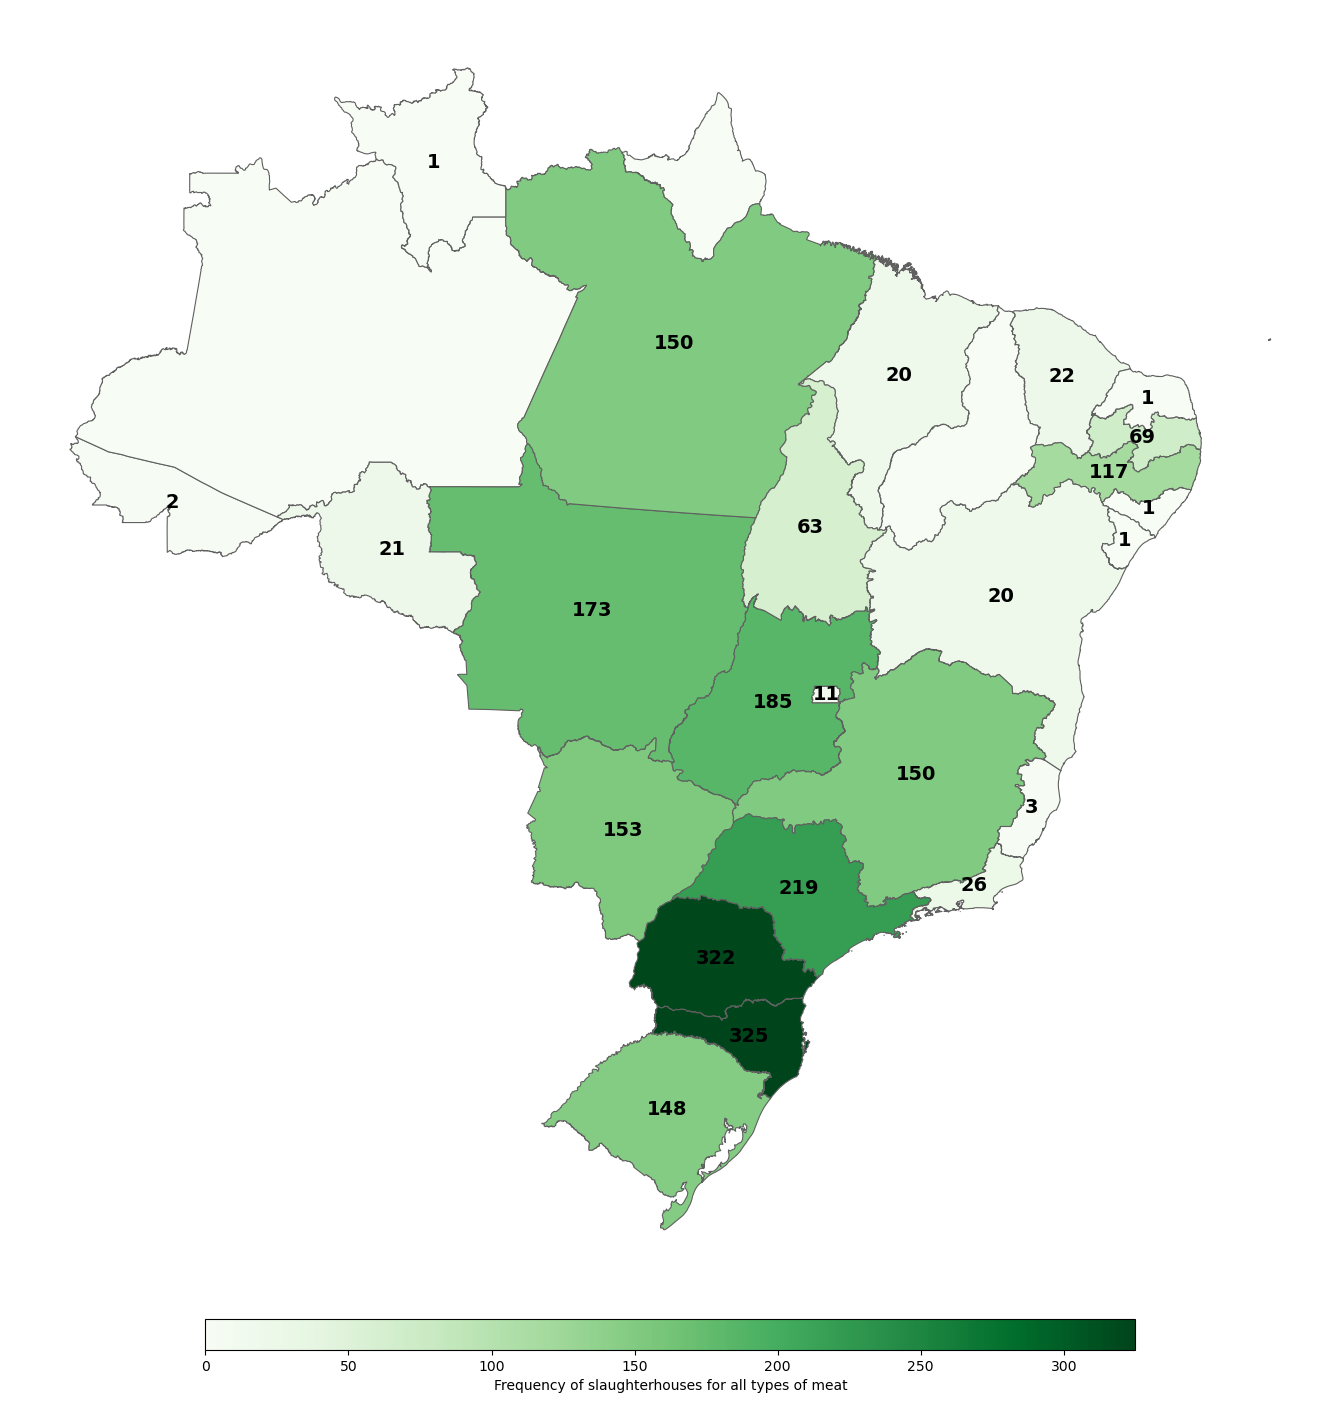

In [3321]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Path to the GeoJSON file
geojson_url = "entrada/brazil-states.geojson"

# Load data
estados = gpd.read_file(geojson_url)
estado_frequencia = df["uf_frigo"].value_counts()
estados["freq"] = estados["sigla"].map(estado_frequencia).fillna(0)

# 1. Increase Figure Size (Standard A4 width is approx 8 inches, so 20 is very large/high quality)
fig, ax = plt.subplots(1, 1, figsize=(20, 20))

# 2. Plot with improved aesthetics
estados.plot(
    column="freq",
    ax=ax,
    legend=True,
    edgecolor="#606060",  # Darker grey for better contrast
    linewidth=0.8,        # Slightly thicker lines
    cmap="Greens",
    legend_kwds={
        "label": "Frequency of slaughterhouses for all types of meat",
        "orientation": "horizontal",
        "shrink": 0.6,    # Make the legend bar shorter
        "pad": 0.02,      # Move legend closer to the map
        "aspect": 30      # Make the legend bar thinner
    },
)

# 3. Improve Labels (Font size, Bold text, Only show non-zero values)
for x, y, label in zip(
    estados.centroid.x, estados.centroid.y, (estados["freq"].astype(int))
):
    # Only label states that actually have data (optional, remove 'if' to show all)
    if label > 0:
        ax.text(
            x, y, 
            label, 
            color="black", 
            fontsize=14,       # Larger text
            fontweight="bold", # Bold text
            ha="center", 
            va="center"
        )

# Remove axis
plt.axis("off")

# 4. Save with High Resolution and Tight Bounding Box
plt.savefig(
    "saida/carne_total_high_res.png", 
    dpi=600,               # High resolution for print
    bbox_inches='tight',   # Removes extra white space
    pad_inches=0.1         # Small padding around the image
)

plt.show()

In [3322]:
df.carne.value_counts().index

Index(['Carne bovina', 'Frango', 'suina'], dtype='object', name='carne')

/var/folders/bp/64w2_y254b14x57_vbv1x62r0000gn/T/ipykernel_47951/2912907933.py:33: UserWarning:

Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.




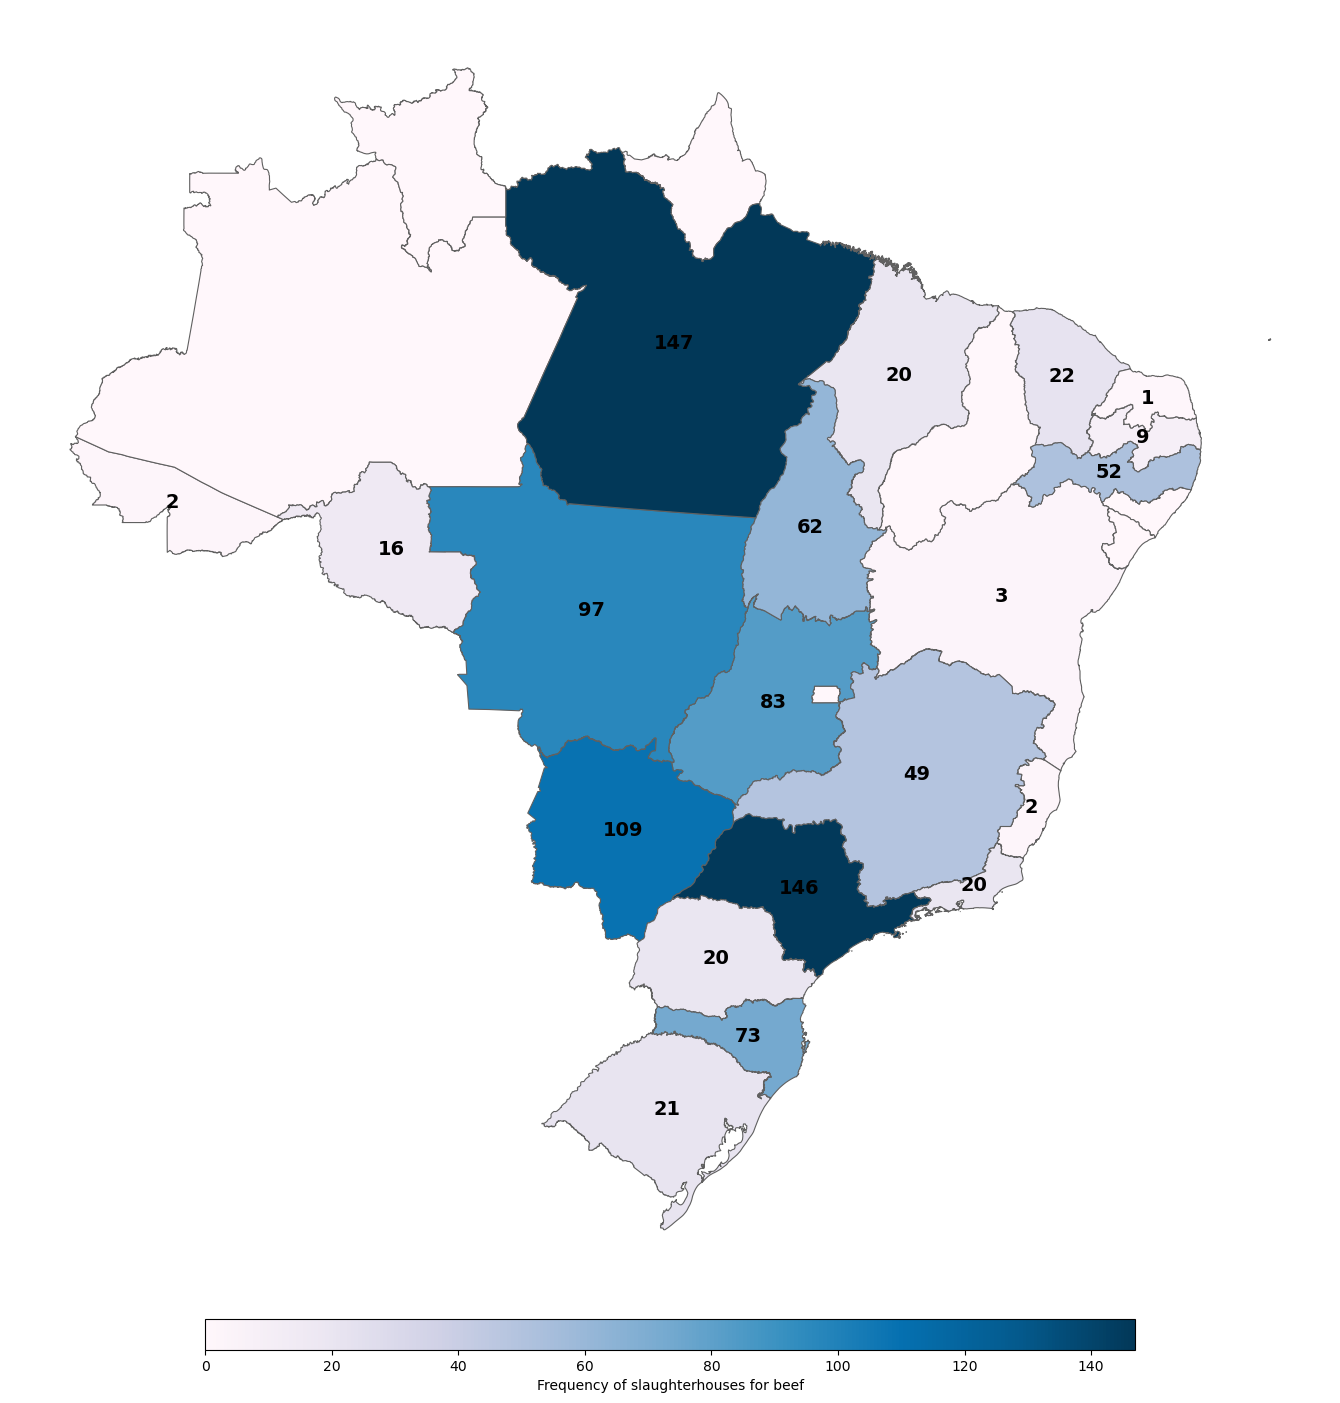

In [3323]:
# 1. Filter data for Beef only ("Carne bovina")
df_beef = df[df.carne == "Carne bovina"]

# 2. Calculate frequency of each state for Beef
beef_frequency = df_beef["uf_frigo"].value_counts()

# 3. Map the frequency back to the GeoDataFrame
# Fill missing values with 0 so the map plots correctly
estados["freq"] = estados["sigla"].map(beef_frequency).fillna(0)

# 4. Initialize the plot with high-quality dimensions
fig, ax = plt.subplots(1, 1, figsize=(20, 20))

# 5. Create the choropleth map
estados.plot(
    column="freq",
    ax=ax,
    legend=True,
    cmap="PuBu",          # Purple-Blue colormap specific for Beef
    edgecolor="#606060",  # Darker grey for better definition
    linewidth=0.8,        # Slightly thicker lines
    legend_kwds={
        "label": "Frequency of slaughterhouses for beef",
        "orientation": "horizontal",
        "shrink": 0.6,    # Compact legend
        "pad": 0.02,      # Closer to map
        "aspect": 30      # Thinner bar
    },
)

# 6. Annotate the map (Smart Labeling)
for x, y, label in zip(
    estados.centroid.x, estados.centroid.y, (estados["freq"].astype(int))
):
    # Only label states that have data (avoid cluttering with '0')
    if label > 0:
        ax.text(
            x, y, 
            label, 
            color="black", 
            fontsize=14,       # Larger text for readability
            fontweight="bold", # Bold text
            ha="center", 
            va="center"
        )

# 7. Final adjustments and saving
plt.axis("off")
plt.savefig(
    "saida/bovina_high_res.png", 
    dpi=600,              # High resolution for print
    bbox_inches='tight',  # Remove extra white space
    pad_inches=0.1
)

plt.show()

/var/folders/bp/64w2_y254b14x57_vbv1x62r0000gn/T/ipykernel_47951/1663333944.py:36: UserWarning:

Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.




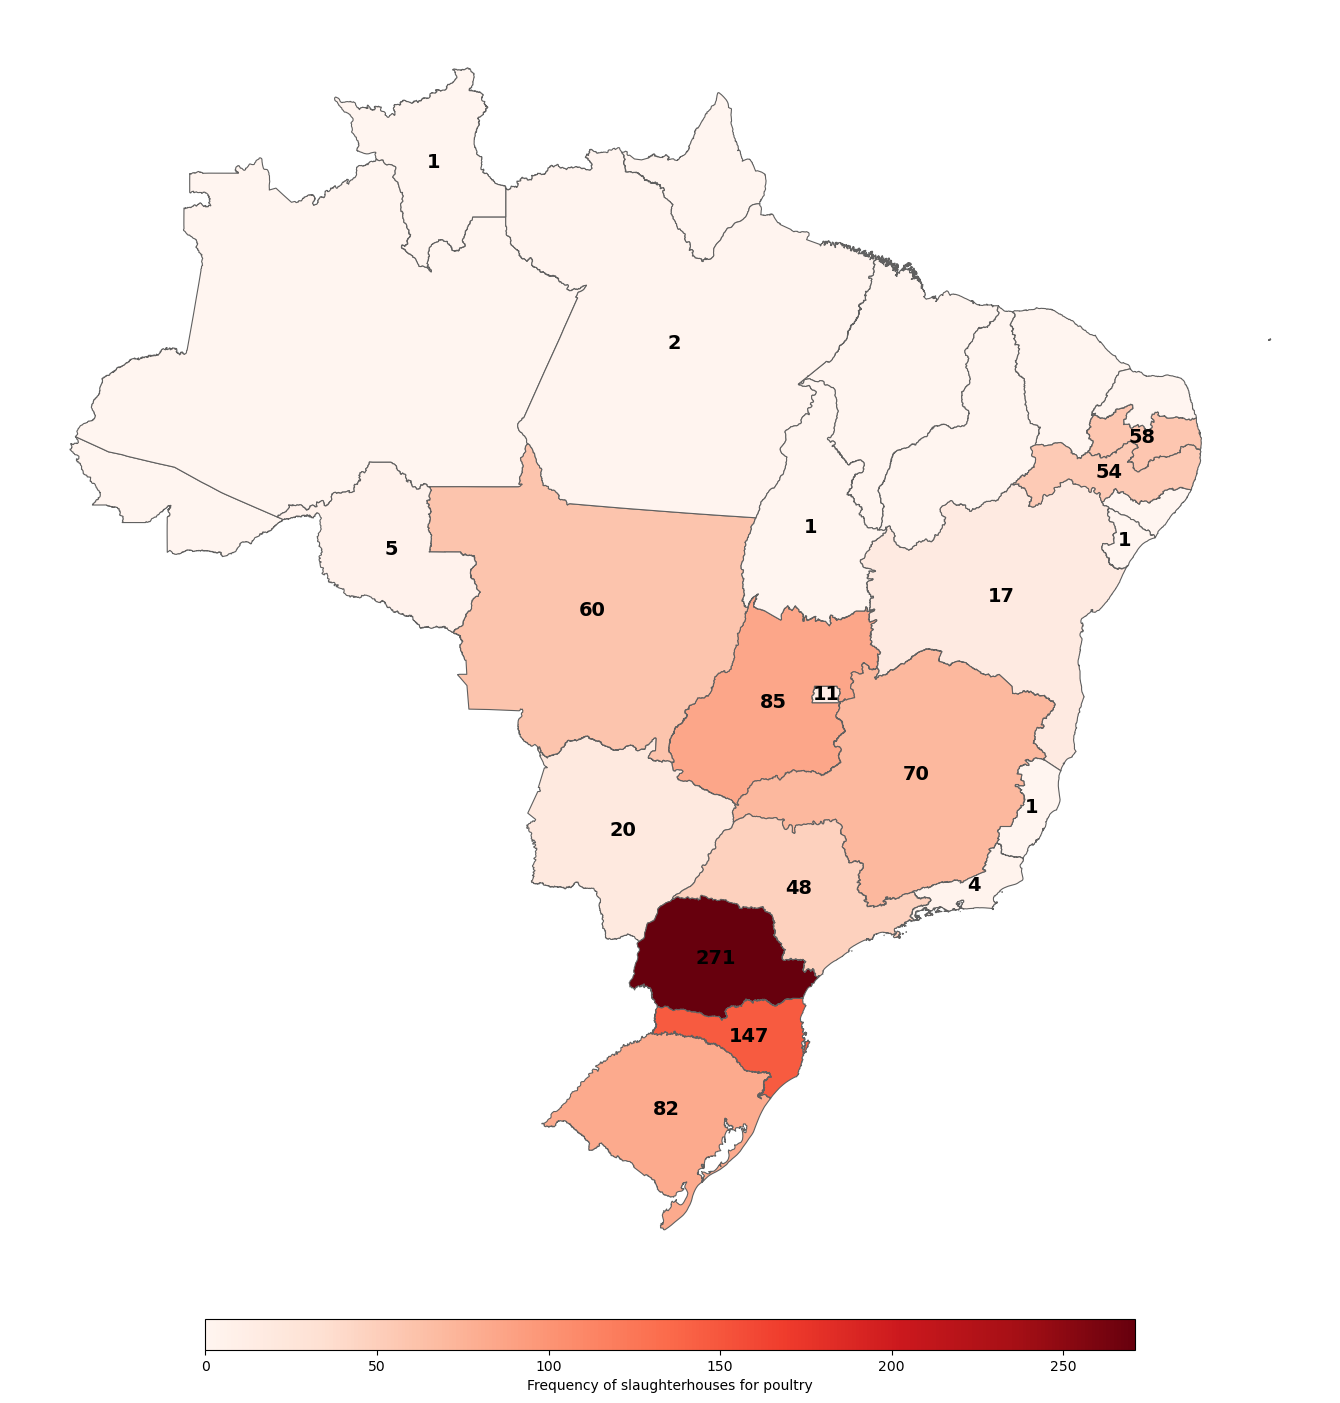

In [3324]:
import geopandas as gpd
import matplotlib.pyplot as plt

#Filter data for Poultry only ("Frango")
df_poultry = df[df.carne == "Frango"]

#Calculate frequency of each state for Poultry
poultry_frequency = df_poultry["uf_frigo"].value_counts()

#Map the frequency back to the GeoDataFrame
# Fill missing values with 0 so the map plots correctly
estados["freq"] = estados["sigla"].map(poultry_frequency).fillna(0)

#Initialize the plot with high-quality dimensions
fig, ax = plt.subplots(1, 1, figsize=(20, 20))

#Create the choropleth map
estados.plot(
    column="freq",
    ax=ax,
    legend=True,
    edgecolor="#606060",  
    linewidth=0.8,        
    cmap="Reds",         
    legend_kwds={
        "label": "Frequency of slaughterhouses for poultry",
        "orientation": "horizontal",
        "shrink": 0.6,  
        "pad": 0.02,     
        "aspect": 30      
    },
)

#Annotate the map (Smart Labeling)
for x, y, label in zip(
    estados.centroid.x, estados.centroid.y, (estados["freq"].astype(int))
):
    # Only label states that have data (avoid cluttering with '0')
    if label > 0:
        ax.text(
            x, y, 
            label, 
            color="black", 
            fontsize=14,       
            fontweight="bold", 
            ha="center", 
            va="center"
        )

#Final adjustments and saving
plt.axis("off")
plt.savefig(
    "saida/frango_high_res.png", 
    dpi=600,              
    bbox_inches='tight',  
    pad_inches=0.1
)

plt.show()

/var/folders/bp/64w2_y254b14x57_vbv1x62r0000gn/T/ipykernel_47951/469973771.py:36: UserWarning:

Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.




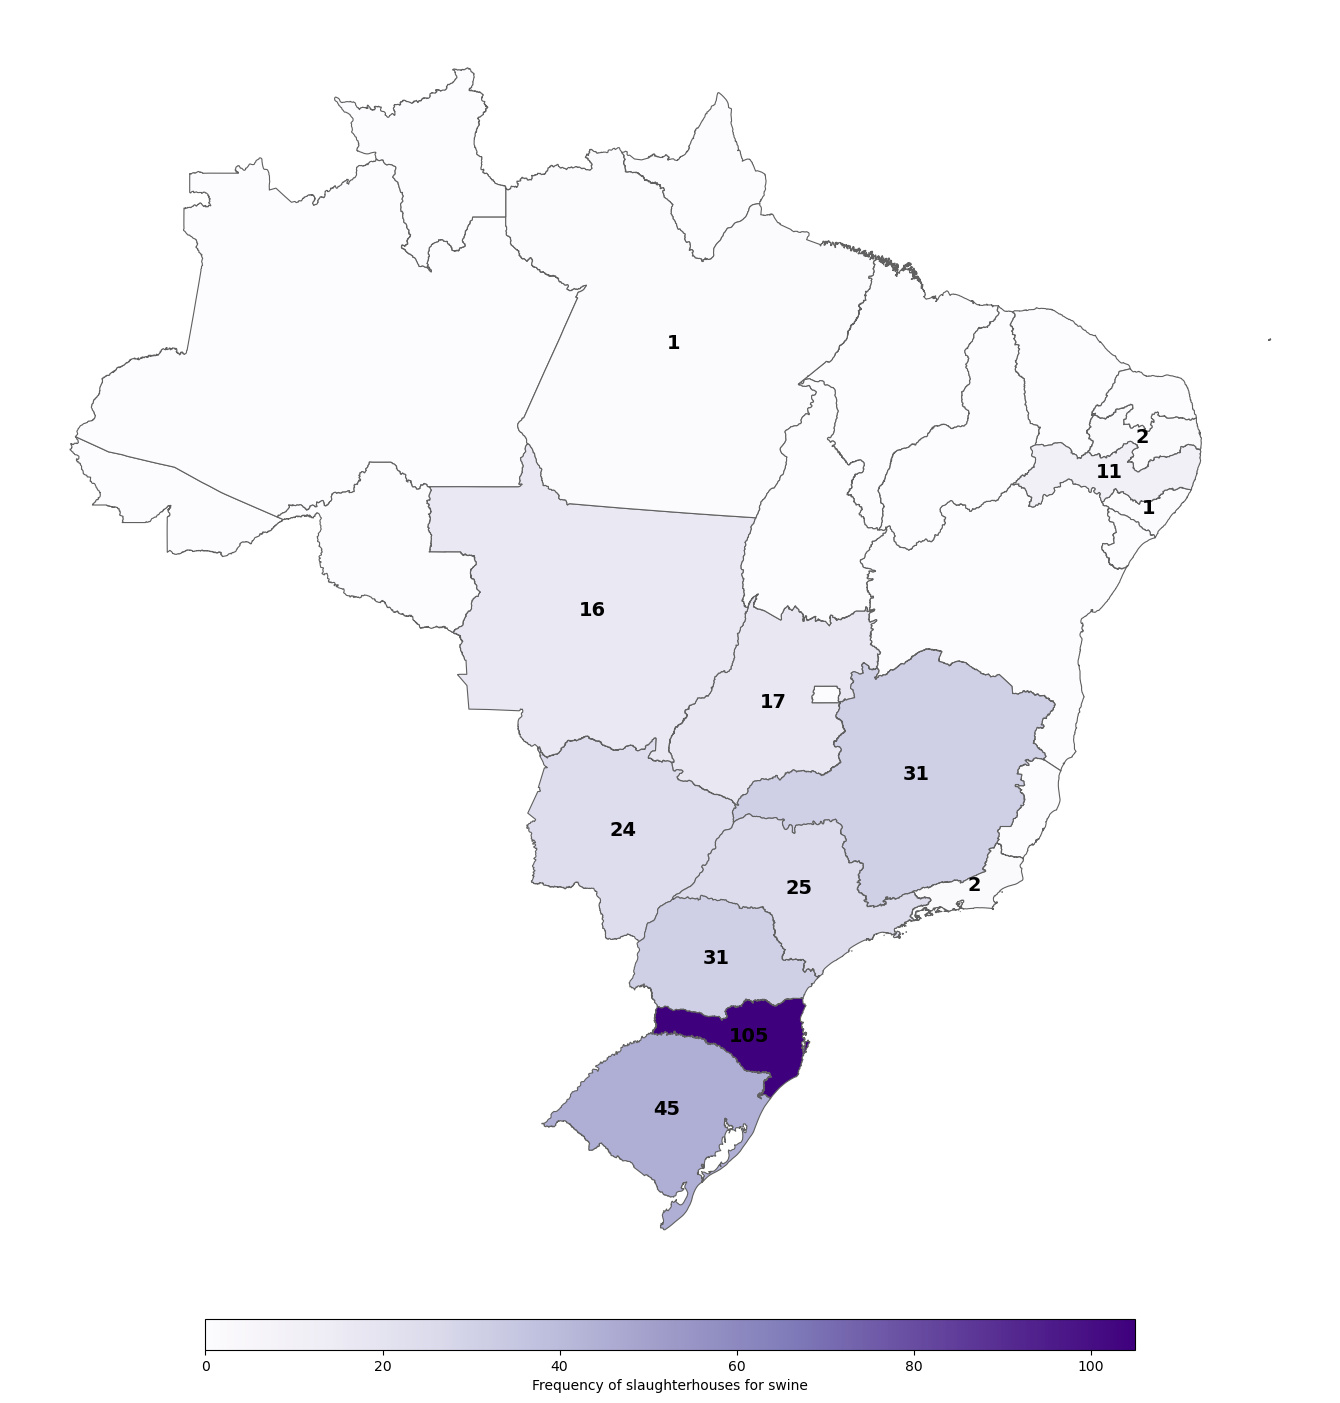

In [3325]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Filter data for Pork only ("suina")
df_pork = df[df.carne == "suina"]

# Calculate frequency of each state for Pork
pork_frequency = df_pork["uf_frigo"].value_counts()

# Map the frequency back to the GeoDataFrame
# Fill missing values with 0 so the map plots correctly
estados["freq"] = estados["sigla"].map(pork_frequency).fillna(0)

#Initialize the plot with high-quality dimensions
fig, ax = plt.subplots(1, 1, figsize=(20, 20))

#Create the choropleth map
estados.plot(
    column="freq",
    ax=ax,
    legend=True,
    edgecolor="#606060",  
    linewidth=0.8,        
    cmap="Purples",       
    legend_kwds={
        "label": "Frequency of slaughterhouses for swine", # 
        "orientation": "horizontal",
        "shrink": 0.6,    
        "pad": 0.02,      
        "aspect": 30     
    },
)

#Annotate the map (Smart Labeling)
for x, y, label in zip(
    estados.centroid.x, estados.centroid.y, (estados["freq"].astype(int))
):
    # Only label states that have data (avoid cluttering with '0')
    if label > 0:
        ax.text(
            x, y, 
            label, 
            color="black", 
            fontsize=14,       
            fontweight="bold", 
            ha="center", 
            va="center"
        )

#Final adjustments and saving
plt.axis("off")
plt.savefig(
    "saida/suina_high_res.png", 
    dpi=600,              
    bbox_inches='tight',  
    pad_inches=0.1
)

plt.show()

# Hypotheses and Variables

## Hypothesis 1 - Larger retailers sell meat sourced from greater distances

* **Independent Variable (IV):** Retailer size (`porte_loja`)
* **Dependent Variable (DV):** Distance from origin (`distancia_km`) - All meat types
* **Covariate:** Census tract income (`renda_setor`)

In [3326]:
# Reset the index of the DataFrame to ensure it is continuous
df.reset_index(drop=True, inplace=True)

# Check for any missing values (NaN) in the columns
print(df.isnull().any())

ID                           False
nome_da_loja                 False
endereco_da_loja             False
loja_municipio               False
lng_loja                     False
lat_loja                     False
carne                        False
nivel_de_inspecao             True
num_de_inspecao               True
nome_do_frigo                 True
frigo_tipo                    True
uf_frigo                      True
lng_frigo                     True
lat_frigo                     True
est_desempenho_sanitario      True
desc_desempenho_sanitario     True
distancia_km                  True
cod_setor                     True
renda_setor                   True
porte_loja                    True
processamento                 True
dtype: bool


In [3327]:
# Remove rows where census tract income data ('renda_setor') is missing
df.dropna(subset=["renda_setor"], inplace=True)

In [3328]:
# Convert retailer size ('porte_loja') to a categorical data type
df["porte_loja"] = df["porte_loja"].astype("category")

In [3329]:
import plotly.express as px

#Dictionary to translate Retailer Size categories to English
mapping_dict = {
    "Acougue": "Butcher shops",
    "Atacarejo/Clubes": "Wholesale clubs",
    "Conveniência": "Convenience store",
    "Hiper/Supercenter": "Supercenters",
    "Sortimento limitado": "Limited-assortment",
    "Supermercado": "Supermarkets"
}

df["porte_loja"] = df["porte_loja"].replace(mapping_dict)

#Create the Box Plot with High-Quality Settings
fig = px.box(
    df,
    x="porte_loja",
    y="distancia_km",
    title="Meat Sourcing Distance by Retailer Type",
    labels={
        "porte_loja": "",
        "distancia_km": "Distance from Origin (km)",
    },
    color="porte_loja",       
    template="plotly_white",  
)

# 3. Refine Layout for Publication Quality
fig.update_layout(
    title_x=0.5,           
    font=dict(
        family="Arial",    
        size=14,           
        color="black"
    ),
    showlegend=False,      
    yaxis=dict(
        showgrid=True,             
        gridcolor='lightgrey',     
        zeroline=False,             
    ),
    xaxis=dict(
        showgrid=False,            
        linecolor='white'          
    ),
    # Optional: Set specific figure dimensions for consistent export quality
    # width=1000,
    # height=600,
)

# 4. Save and Display
fig.write_html("saida/hipotese1_translated.html")
fig.show()

/opt/anaconda3/lib/python3.11/site-packages/plotly/express/_core.py:1958: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



In [3330]:
import plotly.express as px
#Ensure Retailer Types are in English if not already applied

mapping_dict = {
    "Acougue": "Butcher shops",
    "Atacarejo/Clubes": "Wholesale clubs",
    "Conveniência": "Convenience store",
    "Hiper/Supercenter": "Supercenters",
    "Sortimento limitado": "Limited-assortment",
    "Supermercado": "Supermarkets"
}
# Only apply if the values are still in Portuguese
if df["porte_loja"].isin(["Acougue", "Supermercado"]).any():
    df["porte_loja"] = df["porte_loja"].replace(mapping_dict)

#Create the Scatter Plot
# Visualizing the relationship between Neighborhood Income and Sourcing Distance
# 'trendline="ols"' adds an Ordinary Least Squares regression line to check for correlations
fig = px.scatter(
    df,
    x="renda_setor",
    y="distancia_km",
    color="porte_loja",
    title="Census Tract Income vs. Meat Sourcing Distance",
    labels={
        "renda_setor": "Census Tract Income (BRL)", # BRL or R$
        "distancia_km": "Distance from Origin (km)",
        "porte_loja": "Retailer Type",
    },
    trendline="ols",         
    template="plotly_white",  
)

#Refine Layout
fig.update_layout(
    title_x=0.5,              
    font=dict(size=14),       
    legend=dict(
        title="Retailer Type",
        yanchor="top",
        y=0.99,
        xanchor="left",
        x=1.02                
    ),
    xaxis=dict(
        showgrid=True,
        gridcolor='lightgrey'
    ),
    yaxis=dict(
        showgrid=True,
        gridcolor='lightgrey'
    )
)

#Save and Display
fig.write_html("saida/hipotese1_acessorio_renda_translated.html")
fig.show()

/opt/anaconda3/lib/python3.11/site-packages/plotly/express/_core.py:1958: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



In [3331]:
df.groupby("porte_loja")["distancia_km"].describe()

/var/folders/bp/64w2_y254b14x57_vbv1x62r0000gn/T/ipykernel_47951/494341450.py:1: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



,count,mean,std,min,25%,50%,75%,max
porte_loja,,,,,,,,
Butcher shops,82.0,2341.079965,724.201536,105.203464,1956.444463,2450.738408,2882.849757,3935.429160
Wholesale clubs,648.0,2207.263716,822.945185,105.198464,1814.848867,2407.202108,2880.136952,3463.317935
Convenience store,63.0,2395.368906,627.459037,122.138121,2163.463053,2406.571699,2875.587967,3163.111249
Supercenters,33.0,1806.469437,866.454392,221.862241,1474.096078,1499.184873,2320.238921,3282.762795
Limited-assortment,154.0,2151.295937,844.850630,116.985861,1873.426730,2289.670349,2819.573841,3181.309642
Supermarkets,1214.0,2178.201472,823.719203,104.529478,1837.243068,2370.859683,2872.694998,3225.057481


In [3332]:
# ANCOVA Assumption Check: Independence of the Covariate and Independent Variable
# We need to verify if the covariate (Census Tract Income) shares a relationship with the Independent Variable (Retailer Size).

import statsmodels.api as sm
from statsmodels.formula.api import ols

modelo_pressuposto1 = ols("renda_setor ~ C(porte_loja)", data=df).fit()

# Display the summary of the regression
# INTERPRETATION GUIDE:
# Look at the 'Prob (F-statistic)'.
# - If p < 0.05: The assumption is VIOLATED (Income varies significantly by Store Size).
#   -> Conclusion: You cannot use ANCOVA. You should use a GLM or another approach.
print(modelo_pressuposto1.summary())

                            OLS Regression Results                            
Dep. Variable:            renda_setor   R-squared:                       0.055
Model:                            OLS   Adj. R-squared:                  0.053
Method:                 Least Squares   F-statistic:                     25.66
Date:                Wed, 03 Dec 2025   Prob (F-statistic):           3.05e-25
Time:                        15:56:53   Log-Likelihood:                -18538.
No. Observations:                2194   AIC:                         3.709e+04
Df Residuals:                    2188   BIC:                         3.712e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                          coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
In

In [3333]:
#Then, change to GLM approach 

import statsmodels.api as sm
import pandas as pd

#One-Hot Encoding for Categorical Variables
# Convert 'porte_loja' (Retailer Size) into dummy variables (0/1).
df = pd.get_dummies(df, columns=["porte_loja"], drop_first=True)

# Identify the newly created dummy columns
dummy_columns = [col for col in df.columns if "porte_loja_" in col]

# Define the Independent Variables (Predictors)
# Combining the Retailer Size dummies with the Covariate 'renda_setor' (Census Income)
independent_vars = dummy_columns + ["renda_setor"]

# Prepare the Design Matrices
X = df[independent_vars]  # Predictors
y = df["distancia_km"]    # Dependent Variable (Response)

#Check data types to ensure compatibility
print("Predictor types:\n", X.dtypes)
print("Response type:", y.dtype)

# Ensure all inputs are strictly numerical (Float)
X = X.astype(float)

# Add the Intercept (Constant)
X = sm.add_constant(X)

# Fit the Generalized Linear Model (GLM)
# Family: Gaussian (Normal) is chosen because the response variable 'distancia_km' is continuous.
# Link Function: The default link for Gaussian is 'Identity' (meaning no transformation is applied yet).
modelo_glm = sm.GLM(y, X, family=sm.families.Gaussian()).fit()

# Display the statistical summary
print(modelo_glm.summary())


Predictor types:
 porte_loja_Wholesale clubs          bool
porte_loja_Convenience store        bool
porte_loja_Supercenters             bool
porte_loja_Limited-assortment       bool
porte_loja_Supermarkets             bool
renda_setor                      float64
dtype: object
Response type: float64
                 Generalized Linear Model Regression Results                  
Dep. Variable:           distancia_km   No. Observations:                 2194
Model:                            GLM   Df Residuals:                     2187
Model Family:                Gaussian   Df Model:                            6
Link Function:               Identity   Scale:                      6.6792e+05
Method:                          IRLS   Log-Likelihood:                -17823.
Date:                Wed, 03 Dec 2025   Deviance:                   1.4607e+09
Time:                        15:56:53   Pearson chi2:                 1.46e+09
No. Iterations:                     3   Pseudo R-squ. (CS):        

Shapiro-Wilk Test Statistic: 0.8706
P-value: 2.7464e-39
--------------------------------------------------
CONCLUSION:
The residuals do NOT appear to be normally distributed (Reject H0).
>> The standard Gaussian assumption is violated.
>> RECOMMENDATION: Apply a Logarithmic Transformation (Log-Linear Model).
--------------------------------------------------


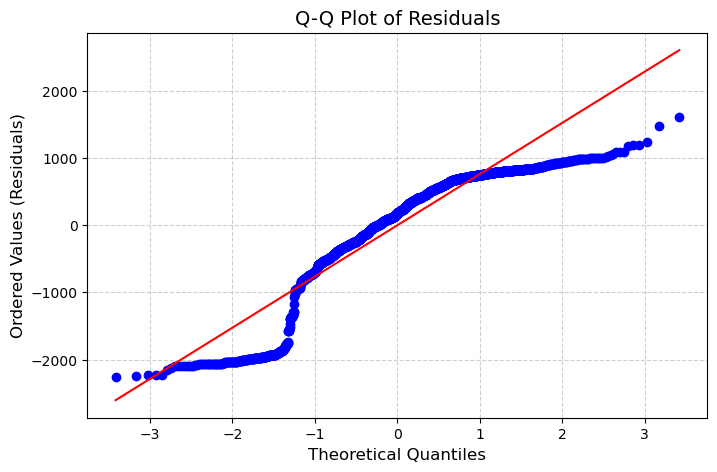

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning:

use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.



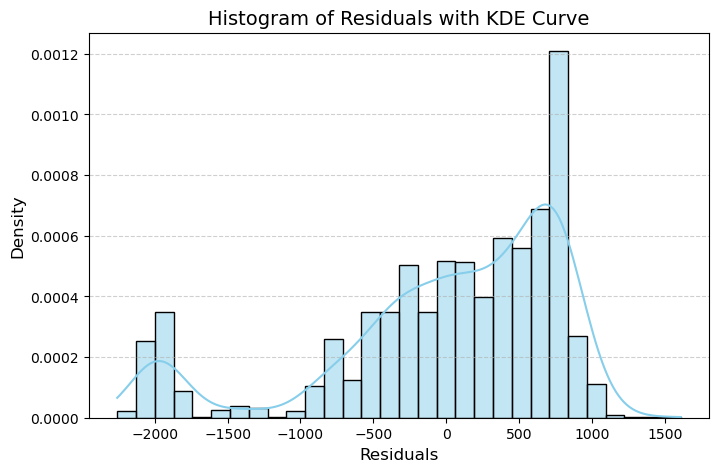

In [3334]:
###Assessing the validity of the Gaussian distribution assumption for the initial GLM.
#Formal Test: Shapiro-Wilk test.
#Visual Inspection: Q-Q plots and Histograms with Kernel Density Estimation (KDE)

import numpy as np
import statsmodels.api as sm
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Get the residuals from the fitted GLM model
# (Assuming 'modelo_glm' is your fitted model object)
residuals = modelo_glm.resid_response

# 2. Shapiro-Wilk Test for Normality
statistic, p_value = stats.shapiro(residuals)

print(f"Shapiro-Wilk Test Statistic: {statistic:.4f}")
print(f"P-value: {p_value:.4e}")  # Scientific notation for very small numbers

# 3. Decision Logic (Gaussian vs. Log Justification)
print("-" * 50)
print("CONCLUSION:")
if p_value > 0.05:
    print("The residuals appear to be normally distributed (Fail to reject H0).")
    print(">> The standard Gaussian model is adequate.")
else:
    print("The residuals do NOT appear to be normally distributed (Reject H0).")
    print(">> The standard Gaussian assumption is violated.")
    print(">> RECOMMENDATION: Apply a Logarithmic Transformation (Log-Linear Model).")
print("-" * 50)

# 4. Visualization: Q-Q Plot
plt.figure(figsize=(8, 5))
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Q-Q Plot of Residuals", fontsize=14)
plt.xlabel("Theoretical Quantiles", fontsize=12)
plt.ylabel("Ordered Values (Residuals)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.savefig("saida/residuals_qqplot.png", dpi=300, bbox_inches="tight")
plt.show()

# 5. Visualization: Histogram with KDE
plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True, bins=30, stat="density", color="skyblue", edgecolor="black")
plt.title("Histogram of Residuals with KDE Curve", fontsize=14)
plt.xlabel("Residuals", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.grid(True, axis='y', linestyle="--", alpha=0.6)
plt.savefig("saida/residuals_histogram.png", dpi=300, bbox_inches="tight")
plt.show()


In [3335]:
### GLM Model (Log-Linear)
#Fit a Generalized Linear Model (GLM) using a Gaussian family with a log-transformed dependent variable to correct for non-normal residuals observed in the previous step.

import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

#Transform the dependent variable (Log-Transformation)
y_transformed = np.log(y)

#Fit the GLM Model (Log-Linear)
modelo_glm_transformado = sm.GLM(y_transformed, X, family=sm.families.Gaussian()).fit()

# Print the statistical summary to the console 
print(modelo_glm_transformado.summary())

#Save the Summary as an Image
summary_str = modelo_glm_transformado.summary().as_text()

# Create a figure to render the text
plt.figure(figsize=(10, 6))
plt.text(
    0.01, 0.05,
    summary_str,
    {"fontsize": 10},
    fontname="Monospace"  # Monospace font ensures proper table alignment
)

# Remove axes
plt.axis("off")
plt.tight_layout()

# Save the file
plt.savefig("saida/modelo_glm_transformado_summary.png", dpi=300, bbox_inches="tight")

# Close the plot to prevent it from showing up a second time in the notebook
plt.close()

                 Generalized Linear Model Regression Results                  
Dep. Variable:           distancia_km   No. Observations:                 2194
Model:                            GLM   Df Residuals:                     2187
Model Family:                Gaussian   Df Model:                            6
Link Function:               Identity   Scale:                         0.58560
Method:                          IRLS   Log-Likelihood:                -2522.6
Date:                Wed, 03 Dec 2025   Deviance:                       1280.7
Time:                        15:56:55   Pearson chi2:                 1.28e+03
No. Iterations:                     3   Pseudo R-squ. (CS):           0.004610
Covariance Type:            nonrobust                                         
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

## Conclusion

Hypothesis 1 was not supported by the data. Contrary to the expectation that larger retailers would source products from further away, the analysis revealed that Supercenters obtain meat from significantly shorter distances than Wholesale clubs and Supermarkets.

### Hypothesis 2: Larger retailers sell more ultra-processed foods

#Independent Variable (IV): Retailer size (`porte_loja`)
#Dependent Variable (DV): Level of processing (`processamento`) - *Categories: Minimally processed, Processed, Ultra-processed*
#Covariate: Census tract income (`renda_setor`)
#Statistical Method: Multinomial Logistic Regression

In [3336]:
import pandas as pd
import numpy as np # Needed for np.nan conversion

#Load the raw dataset
df = pd.read_csv("entrada/20240615_carnestotais_att.csv")

#Define critical variables required for the statistical model
critical_columns = ["porte_loja", "renda_setor", "processamento"]

#Replace explicit empty spaces (" ") in 'processamento' with NaN.
#Drop any row that is NaN in any of the critical columns.
df_processamento = (
    df.replace({"processamento": {" ": np.nan}})
    .dropna(subset=critical_columns)
    .copy()
)

#Display the prepared DataFrame and its new size
print(f"DataFrame dimensions after cleaning: {df_processamento.shape}")
df_processamento.head()

DataFrame dimensions after cleaning: (156, 21)


,ID,nome_da_loja,endereco_da_loja,loja_municipio,lng_loja,lat_loja,carne,nivel_de_inspecao,num_de_inspecao,nome_do_frigo,frigo_tipo,uf_frigo,lng_frigo,lat_frigo,est_desempenho_sanitario,desc_desempenho_sanitario,distancia_km,cod_setor,renda_setor,porte_loja,processamento
0,frango747,3667,"RUA GENERINA VALE,809, CENTRO - Rua Joel Damas...",Caico,"-35,202074","-5,836721",Frango,SIF,3667,GUARAVES GUARABIRA AVES,AA1 - AVES - MAIS DE 3000/H|ABATEDOURO FRIGORI...,PB,"-35,48996498","-6,852715",NaN,NaN,"116,784358",2.408102e+14,"4029,68",Supermercado,ultraprocessado
2,boi865,Açougue Pai e Filho,"R. São Sebastião, Macaíba - RN, 59280-000",Macaiba,"-35,34895744","-5,852689182",Carne bovina,SIF,76,JBS,UNIDADE DE BENEF. DE CARNE E PROD. CARNEOS - C...,SP,"-48,56737784","-20,55845552",4.0,"Frigorífico habilitado para a exportação, com ...","2164,837028",2.407104e+14,"628,31",Conveniência,ultraprocessado
5,boi3,Ary Coiffure - Carrefour,"CARREFOUR - AV. SEN. SALGADO FILHO, 3700 - LOJ...",Natal,"-35,2099","-5,8455",Carne bovina,SIF,791,MINERVA,"ABATEDOURO FRIGORIFICO - C15, AB1 - BOVINO - M...",RO,"-61,8057425","-11,7254349",5.0,"Frigorífico habilitado para a exportação, com ...","2995,570405",2.408102e+14,"2754,04",Hiper/Supercenter,ultraprocessado
6,boi4,Ary Coiffure - Carrefour,"CARREFOUR - AV. SEN. SALGADO FILHO, 3700 - LOJ...",Natal,"-35,2099","-5,8455",Carne bovina,SIF,860,MASTERBOI,"ABATEDOURO FRIGORIFICO - C15, AB3 - BOVINO - 4...",TO,"-48,42480679","-7,633314911",4.0,"Frigorífico habilitado para a exportação, com ...","1474,191415",2.408102e+14,"2754,04",Hiper/Supercenter,ultraprocessado
7,boi5,Ary Coiffure - Carrefour,"CARREFOUR - AV. SEN. SALGADO FILHO, 3700 - LOJ...",Natal,"-35,2099","-5,8455",Carne bovina,SIF,860,MASTERBOI,"ABATEDOURO FRIGORIFICO - C15, AB3 - BOVINO - 4...",TO,"-48,42480679","-7,633314911",4.0,"Frigorífico habilitado para a exportação, com ...","1474,191415",2.408102e+14,"2754,04",Hiper/Supercenter,minimamente processado


In [3337]:
import pandas as pd
import plotly.express as px

#Setup Data 
retailer_map = {
    "Acougue": "Butcher shops",
    "Atacarejo/Clubes": "Wholesale clubs",
    "Conveniência": "Convenience store",
    "Hiper/Supercenter": "Supercenters",
    "Sortimento limitado": "Limited-assortment",
    "Supermercado": "Supermarkets",
}

processing_map = {
    "minimamente processado ": "Minimally processed foods",
    "processado": "Processed foods",
    "ultraprocessado": "Ultra-processed foods",
}

df_processamento["porte_loja"] = df_processamento["porte_loja"].replace(retailer_map)
df_processamento["processamento"] = df_processamento["processamento"].replace(processing_map)

# Calculate Frequencies
processing_distribution = (
    df_processamento.groupby("porte_loja")["processamento"]
    .value_counts(normalize=True)
    .unstack()
    .fillna(0)
    .stack()
    .reset_index(name="relative_frequency")
)

#Visualization Setup
custom_colors = ["#ADD8E6", "#87CEEB", "#4682B4"] # Blue Palette

fig = px.bar(
    processing_distribution,
    x="porte_loja",
    y="relative_frequency",
    color="processamento",
    barmode="group",
    title="",
    category_orders={
        "processamento": ["Minimally processed foods", "Processed foods", "Ultra-processed foods"]
    },
    color_discrete_sequence=custom_colors,
    template="plotly_white",
    height=700,
    width=1000
)

# Refine Layout
fig.update_layout(
    font=dict(family="Arial", size=14, color="black"),
    title=dict(x=0.5),
    
    # Gap Settings
    bargap=0.3,      
    bargroupgap=0.1, 
    
    xaxis=dict(
        title="",
        showgrid=False,
        linecolor="black"
    ),
    yaxis=dict(
        title="Frequency",
        tickformat=".0%",
        showgrid=True,
        gridcolor="#E5E5E5"
    ),
    
    legend=dict(
        title="Food Processing Level",
        orientation="h",       
        yanchor="bottom",      
        y=1.02,                
        xanchor="center",      
        x=0.5,                 
        bgcolor="rgba(255, 255, 255, 0.9)",
        borderwidth=0
    ),
    
    margin=dict(t=100)
)

# Add Vertical Dividers between Retailers
retailers = processing_distribution["porte_loja"].unique()
for i in range(len(retailers) - 1):
    fig.add_shape(
        type="line",
        x0=i + 0.5, y0=0,
        x1=i + 0.5, y1=1,
        xref="x", yref="paper",
        line=dict(color="lightgrey", width=1, dash="dot")
    )

#Save in High Definition
# Option A: High-Res PNG (Scale 6 = 600 DPI approx)
try:
    fig.write_image("saida/Processing_high_res.png", scale=6)
except Exception as e:
    print(f"Could not save image (check kaleido installation): {e}")

fig.show()

In [3338]:
import pandas as pd
import plotly.express as px

# 1. Load and Clean Data
df = pd.read_csv("entrada/20240615_carnestotais_att.csv")

# Create a dedicated copy to avoid SettingWithCopyWarning
df_processamento = df.dropna(subset=["processamento", "porte_loja"]).copy()

# SAFETY FIX: Strip whitespace to ensure 'minimamente processado' matches correctly
df_processamento["processamento"] = df_processamento["processamento"].str.strip()

# 2. Translations
retailer_map = {
    "Acougue": "Butcher shops",
    "Atacarejo/Clubes": "Wholesale clubs",
    "Conveniência": "Convenience store",
    "Hiper/Supercenter": "Supercenters",
    "Sortimento limitado": "Limited-assortment",
    "Supermercado": "Supermarkets",
}

processing_map = {
    "minimamente processado": "Minimally processed foods", # Removed extra space key
    "processado": "Processed foods",
    "ultraprocessado": "Ultra-processed foods",
}

# Apply translations
df_processamento["porte_loja"] = df_processamento["porte_loja"].replace(retailer_map)
df_processamento["processamento"] = df_processamento["processamento"].replace(processing_map)

# 3. Calculate Absolute Counts
processing_counts = (
    df_processamento.groupby("porte_loja")["processamento"]
    .value_counts(normalize=False) 
    .unstack()
    .fillna(0)
    .stack()
    .reset_index(name="count")
)

# 4. Visualization Setup
custom_colors = ["#ADD8E6", "#87CEEB", "#4682B4"]

# Explicitly define Retailer Order (Alphabetical) to ensure lines align
retailer_order = sorted(processing_counts["porte_loja"].unique())

fig = px.bar(
    processing_counts,
    x="porte_loja",
    y="count",
    color="processamento",
    barmode="group",
    title="Distribution of Processing Levels by Retailer Size (Absolute Count)",
    # Enforce order for BOTH X-axis and Legend
    category_orders={
        "processamento": ["Minimally processed foods", "Processed foods", "Ultra-processed foods"],
        "porte_loja": retailer_order
    },
    color_discrete_sequence=custom_colors,
    template="plotly_white",
    height=700,
    width=1000
)

# 5. Refine Layout
fig.update_layout(
    font=dict(family="Arial", size=14, color="black"),
    title=dict(x=0.5),
    
    bargap=0.3,
    bargroupgap=0.1,
    
    xaxis=dict(
        title="",
        showgrid=False,
        linecolor="black"
    ),
    yaxis=dict(
        title="Count",
        tickformat="d", # 'd' ensures integers (0, 10, 20) instead of floats
        showgrid=True,
        gridcolor="#E5E5E5"
    ),
    
    # Legend
    legend=dict(
        title="Food Processing Level",
        orientation="h",       
        yanchor="bottom",      
        y=1.02,                
        xanchor="center",      
        x=0.5,                 
        bgcolor="rgba(255, 255, 255, 0.9)",
        borderwidth=0
    ),
    
    margin=dict(t=100)
)

# 6. Add Hover Template (Showing Raw Counts)
fig.update_traces(
    hovertemplate="<b>Retailer</b>: %{x}<br>" +
                  "<b>Type</b>: %{data.name}<br>" +
                  "<b>Count</b>: %{y}<extra></extra>"
)

# 7. Add Vertical Dividers
# Since we enforced 'category_orders', the loop logic is now safe
for i in range(len(retailer_order) - 1):
    fig.add_shape(
        type="line",
        x0=i + 0.5, y0=0,
        x1=i + 0.5, y1=1,
        xref="x", yref="paper",
        line=dict(color="lightgrey", width=1, dash="dot")
    )

fig.show()

In [3339]:
# Apply Translation Mappings
df_processamento["porte_loja"] = df_processamento["porte_loja"].replace(mapping_dict)
df_processamento["processamento"] = df_processamento["processamento"].replace(mappping_processamento)

# Generate Contingency Table
# Create a cross-tabulation to observe the frequency of each processing level across retailer types
contingency_table = pd.crosstab(
    df_processamento["porte_loja"], 
    df_processamento["processamento"]
)

contingency_table.index.name = "Retailer Size"
contingency_table.columns.name = "Processing Level"

# Display the table
contingency_table

Processing Level,Minimally processed foods,Processed foods,Ultra-processed foods
Retailer Size,,,
Butcher shops,18,11,9
Convenience store,0,0,6
Limited-assortment,13,0,3
Supercenters,6,1,2
Supermarkets,52,5,36
Wholesale clubs,12,4,4


In [3340]:
import statsmodels.api as sm
import pandas as pd

#Adjust the Covariate 'Census Tract Income' (renda_setor)
#Handle Brazilian number formatting (comma decimal) before conversion
df_processamento["renda_setor"] = df_processamento["renda_setor"].astype("str")
df_processamento["renda_setor"] = (
    df_processamento["renda_setor"]
    .str.replace(",", ".")
    .astype(float) # Final conversion to float
)

#Define the Predictor Matrix (X)
# Identify pre-existing dummy columns (from previous pd.get_dummies step)
dummy_columns = [col for col in df_processamento.columns if "porte_loja_" in col]

#Define Independent Variables: Retailer Size Dummies + Income Covariate
independent_vars = dummy_columns + ["renda_setor"]
X = df_processamento[independent_vars].astype(float) 

#Add Intercept (Constant)
X = sm.add_constant(X)

#Define the Target Variable (y)
y = df_processamento["processamento"]

# 4. Final Target Preparation
# Ensure the target variable is explicitly defined as a Pandas Categorical type.
df_processamento["processamento"] = pd.Categorical(df_processamento["processamento"])

# Update y with the categorical type
y = df_processamento["processamento"]

# Display unique categories to confirm successful definition
unique_values = y.unique()
print("Final Processing Categories:", unique_values)

# Display the prepared Design Matrix (X)
df_processamento.head()

Final Processing Categories: ['Ultra-processed foods', 'Minimally processed foods', 'Processed foods']
Categories (3, object): ['Minimally processed foods', 'Processed foods', 'Ultra-processed foods']


,ID,nome_da_loja,endereco_da_loja,loja_municipio,lng_loja,lat_loja,carne,nivel_de_inspecao,num_de_inspecao,nome_do_frigo,frigo_tipo,uf_frigo,lng_frigo,lat_frigo,est_desempenho_sanitario,desc_desempenho_sanitario,distancia_km,cod_setor,renda_setor,porte_loja,processamento
0,frango747,3667,"RUA GENERINA VALE,809, CENTRO - Rua Joel Damas...",Caico,"-35,202074","-5,836721",Frango,SIF,3667,GUARAVES GUARABIRA AVES,AA1 - AVES - MAIS DE 3000/H|ABATEDOURO FRIGORI...,PB,"-35,48996498","-6,852715",NaN,NaN,"116,784358",2.408102e+14,4029.68,Supermarkets,Ultra-processed foods
1,boi1006,Açougue Pai e Filho,"R. São Sebastião, Macaíba - RN, 59280-000",Macaiba,"-35,34827079","-5,850981514",Carne bovina,SEIPOA,0165,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Convenience store,Ultra-processed foods
2,boi865,Açougue Pai e Filho,"R. São Sebastião, Macaíba - RN, 59280-000",Macaiba,"-35,34895744","-5,852689182",Carne bovina,SIF,76,JBS,UNIDADE DE BENEF. DE CARNE E PROD. CARNEOS - C...,SP,"-48,56737784","-20,55845552",4.0,"Frigorífico habilitado para a exportação, com ...","2164,837028",2.407104e+14,628.31,Convenience store,Ultra-processed foods
3,boi866,Açougue Pai e Filho,"R. São Sebastião, Macaíba - RN, 59280-000",Macaiba,"-3,534930076","-5,851664581",Carne bovina,SIF,3921,NUTRIZA AGROINDUSTRIAL DE ALIMENTOS,ABATEDOURO FRIGORIFICO - C15,GO,"-48,28029255","-17,30058111",4.0,"Frigorífico habilitado para a exportação, com ...","5027,953642",NaN,NaN,Convenience store,Ultra-processed foods
4,frango987,Açougue Pai e Filho,"R. São Sebastião, Macaíba - RN, 59280-000",Macaiba,"-35,34827079","-5,850981514",Frango,SEIPOA,0042,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Convenience store,Ultra-processed foods


In [3341]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

#Encode and Synchronize Variables (Final Data Prep)
#Ensure Y is numerically encoded (0, 1, 2, etc.)
if y.dtype == 'object':
    # Convert string labels to numerical codes (required for MNLogit)
    y_encoded = y.astype('category').cat.codes
else:
    # If already encoded, use the existing series
    y_encoded = y 
    
#Combine X and the encoded Y into a single temporary DataFrame
data_model = pd.concat([y_encoded.rename('y_encoded'), X], axis=1)

#Remove NaNs and Infinities in a synchronized manner (Prevents MissingDataError)
data_clean = data_model.replace([np.inf, -np.inf], np.nan).dropna(axis=0)

#Separate the FINAL clean, synchronized data matrices
y_final = data_clean['y_encoded']
X_final = data_clean.drop(columns=['y_encoded'])

#Fit the Multinomial Logit Model
try:
    print("Fitting MNLogit Model...")
    # Fit the model using the clean, synchronized data
    modelo = sm.MNLogit(y_final, X_final).fit()
    
    print(modelo.summary())

except Exception as e:
    print(f"Error fitting the model: {e}")

Fitting MNLogit Model...
Optimization terminated successfully.
         Current function value: 0.883803
         Iterations 6
                          MNLogit Regression Results                          
Dep. Variable:              y_encoded   No. Observations:                  156
Model:                        MNLogit   Df Residuals:                      152
Method:                           MLE   Df Model:                            2
Date:                Wed, 03 Dec 2025   Pseudo R-squ.:                0.009033
Time:                        15:56:58   Log-Likelihood:                -137.87
converged:                       True   LL-Null:                       -139.13
Covariance Type:            nonrobust   LLR p-value:                    0.2846
      y_encoded=Processed foods       coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const                              -2.453

In [3342]:
#CONTEXTUAL INFORMATION & INTERPRETATION 
print("\n" + "="*80)
print("             CONTEXT FOR INTERPRETING MNLOGIT SUMMARY")
print("="*80)

print("\n[Y] DEPENDENT VARIABLE (PROCESSING LEVEL):")
print("---------------------------------------")
print(" Y=0 (OMITTED/REFERENCE): Minimally processed foods (Fresh Meat)")
print(" Y=1 (PANEL 1): Processed foods (Compared to Baseline 0)")
print(" Y=2 (PANEL 2): Ultra-processed foods (Compared to Baseline 0)")

print("\n[X] INDEPENDENT VARIABLE (RETAILER SIZE):")
print("---------------------------------------")
print(" * The omitted retailer category (Reference) is: **Butcher shops**.")
print(" * All store coefficients measure the odds relative to the Butcher shops baseline.")
print("="*80)

#Print the statistical summary (the original model text output)
print(modelo.summary())


             CONTEXT FOR INTERPRETING MNLOGIT SUMMARY

[Y] DEPENDENT VARIABLE (PROCESSING LEVEL):
---------------------------------------
 Y=0 (OMITTED/REFERENCE): Minimally processed foods (Fresh Meat)
 Y=1 (PANEL 1): Processed foods (Compared to Baseline 0)
 Y=2 (PANEL 2): Ultra-processed foods (Compared to Baseline 0)

[X] INDEPENDENT VARIABLE (RETAILER SIZE):
---------------------------------------
 * The omitted retailer category (Reference) is: **Butcher shops**.
 * All store coefficients measure the odds relative to the Butcher shops baseline.
                          MNLogit Regression Results                          
Dep. Variable:              y_encoded   No. Observations:                  156
Model:                        MNLogit   Df Residuals:                      152
Method:                           MLE   Df Model:                            2
Date:                Wed, 03 Dec 2025   Pseudo R-squ.:                0.009033
Time:                        15:56:58   Log-Lik

In [3343]:
import pandas as pd
import numpy as np

# Prepare Predictor Matrix (X_VIF)
X_vif_input = df_processamento[['porte_loja', 'renda_setor']].copy()

#Generate dummy variables for retailer size, dropping the first category (reference)
X_vif = pd.get_dummies(X_vif_input, columns=['porte_loja'], drop_first=True)

#Ensure all variables are float (required for linear algebra)
X_vif = X_vif.astype(float)

# Calculate VIF Manually via Inverse Correlation Matrix
#The VIF for each predictor is the diagonal element of the inverse of the correlation matrix (R^-1).
try:
    # Calculate the correlation matrix (R)
    corr_matrix = X_vif.corr()
    
    # Invert the correlation matrix (R^-1)
    inv_corr_matrix = np.linalg.inv(corr_matrix.values)
    
    # Create the results DataFrame: VIF_i = diagonal element (i,i) of R^-1
    vif_data = pd.DataFrame()
    vif_data["Variable"] = X_vif.columns
    vif_data["VIF"] = np.diag(inv_corr_matrix)
    
    print("--- VIF Results (Manual Calculation) ---")
    print(vif_data.sort_values(by="VIF", ascending=False))

except Exception as e:
    print(f"Calculation failed. Error: {e}")

--- VIF Results (Manual Calculation) ---
                        Variable       VIF
4        porte_loja_Supermarkets  2.165545
2  porte_loja_Limited-assortment  1.685726
0                    renda_setor  1.677547
5     porte_loja_Wholesale clubs  1.363947
3        porte_loja_Supercenters  1.184979
1   porte_loja_Convenience store  1.180510


## Conclusion

The initial hypothesis that larger retailers sell more ultra-processed foods was REJECTED. Low Explanatory Power: The Pseudo R^2 of 0.009033 confirms that the variables included in the model (Retailer Size and Income) account for less than 1% of the overall variance in processing level.

## Hypothesis 3 - Larger retailers display higher sanitary quality

#Independent Variable (IV): Retailer size (`porte_loja`)
#Dependent Variable (DV): Sanitary performance (`desc_desempenho_sanitario`) - *Beef only*
#Covariate: Census tract income (`renda_setor`)

In [3344]:
import pandas as pd

# Load the dataset
df = pd.read_csv("entrada/20240615_carnestotais_att.csv")

# Filter the dataset to include only Beef ("Carne bovina")
carne_bovina_data = df[df["carne"] == "Carne bovina"]

# Display the filtered DataFrame
carne_bovina_data

,ID,nome_da_loja,endereco_da_loja,loja_municipio,lng_loja,lat_loja,carne,nivel_de_inspecao,num_de_inspecao,nome_do_frigo,frigo_tipo,uf_frigo,lng_frigo,lat_frigo,est_desempenho_sanitario,desc_desempenho_sanitario,distancia_km,cod_setor,renda_setor,porte_loja,processamento
1,boi1006,Açougue Pai e Filho,"R. São Sebastião, Macaíba - RN, 59280-000",Macaiba,"-35,34827079","-5,850981514",Carne bovina,SEIPOA,0165,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Conveniência,ultraprocessado
2,boi865,Açougue Pai e Filho,"R. São Sebastião, Macaíba - RN, 59280-000",Macaiba,"-35,34895744","-5,852689182",Carne bovina,SIF,76,JBS,UNIDADE DE BENEF. DE CARNE E PROD. CARNEOS - C...,SP,"-48,56737784","-20,55845552",4.0,"Frigorífico habilitado para a exportação, com ...","2164,837028",2.407104e+14,"628,31",Conveniência,ultraprocessado
3,boi866,Açougue Pai e Filho,"R. São Sebastião, Macaíba - RN, 59280-000",Macaiba,"-3,534930076","-5,851664581",Carne bovina,SIF,3921,NUTRIZA AGROINDUSTRIAL DE ALIMENTOS,ABATEDOURO FRIGORIFICO - C15,GO,"-48,28029255","-17,30058111",4.0,"Frigorífico habilitado para a exportação, com ...","5027,953642",NaN,NaN,Conveniência,ultraprocessado
5,boi3,Ary Coiffure - Carrefour,"CARREFOUR - AV. SEN. SALGADO FILHO, 3700 - LOJ...",Natal,"-35,2099","-5,8455",Carne bovina,SIF,791,MINERVA,"ABATEDOURO FRIGORIFICO - C15, AB1 - BOVINO - M...",RO,"-61,8057425","-11,7254349",5.0,"Frigorífico habilitado para a exportação, com ...","2995,570405",2.408102e+14,"2754,04",Hiper/Supercenter,ultraprocessado
6,boi4,Ary Coiffure - Carrefour,"CARREFOUR - AV. SEN. SALGADO FILHO, 3700 - LOJ...",Natal,"-35,2099","-5,8455",Carne bovina,SIF,860,MASTERBOI,"ABATEDOURO FRIGORIFICO - C15, AB3 - BOVINO - 4...",TO,"-48,42480679","-7,633314911",4.0,"Frigorífico habilitado para a exportação, com ...","1474,191415",2.408102e+14,"2754,04",Hiper/Supercenter,ultraprocessado
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2323,boi966,Tela Quente,"São Gonçalo do Amarante - Rio Grande do Norte,...",sao goncalo,"-35,27215547","-5,77344728",Carne bovina,SIF,65,BRASA BURGER INDUSTRIA E COMERCIO DE DERIVADOS...,UNIDADE DE BENEF. DE CARNE E PROD. CARNEOS - C...,SP,"-47,37677424","-23,04253672",3.0,"Frigorífico habilitado para a exportação, com ...","2310,721197",2.412005e+14,"810,81",Sortimento limitado,NaN
2324,boi967,Tela Quente,"São Gonçalo do Amarante - Rio Grande do Norte,...",sao goncalo,"-35,27215547","-5,77344728",Carne bovina,SIF,2478,GRANJA BRASILIA AGROINDUSTRIAL AVICOLA,"ABATEDOURO FRIGORIFICO - C15, ENTREPOSTO DE PR...",MG,"-44,05666464","-20,02803775",4.0,"Frigorífico habilitado para a exportação, com ...","1841,330377",2.412005e+14,"810,81",Sortimento limitado,NaN
2325,boi968,Tela Quente,"São Gonçalo do Amarante - Rio Grande do Norte,...",sao goncalo,"-35,27215547","-5,77344728",Carne bovina,SIF,93,COOPERATIVA DOS PRODUTORES DE CARNE E DERIVADO...,"ABATEDOURO FRIGORIFICO - C15, AB3 - BOVINO - 4...",TO,"-49,07147747","-11,72977232",4.0,"Frigorífico habilitado para a exportação, com ...","1654,372179",2.412005e+14,"810,81",Sortimento limitado,NaN
2326,boi969,Tela Quente,"São Gonçalo do Amarante - Rio Grande do Norte,...",sao goncalo,"-35,27215547","-5,77344728",Carne bovina,SIF,51,JBS,"ABATEDOURO FRIGORIFICO - C15, AB2 - BOVINO - M...",MT,"-59,2962784","-15,0823624",4.0,"Frigorífico habilitado para a exportação, com ...","2821,259306",2.412005e+14,"810,81",Sortimento limitado,NaN


In [3345]:
#Standardize the Covariate 'renda_setor' (Census Income)
#Convert to string first to safely handle replace operations
carne_bovina_data["renda_setor"] = carne_bovina_data["renda_setor"].astype(str)

#Replace Brazilian comma decimal separator with dot and convert to float
carne_bovina_data["renda_setor"] = (
    carne_bovina_data["renda_setor"]
    .str.replace(",", ".")
    .astype(float)
)

#Verify data types after conversion
print("Data Types:\n", carne_bovina_data.dtypes)

#Handle Missing Data
#Define critical columns for this specific hypothesis
columns_to_check = ["est_desempenho_sanitario", "porte_loja", "renda_setor"]

#Drop rows where any of these critical variables are missing (NaN)
carne_bovina_data_clean = carne_bovina_data.dropna(subset=columns_to_check)

#Ensure Dependent Variable is Numeric
# Convert 'est_desempenho_sanitario' to numeric, coercing errors to NaN
# This ensures that the Sanitary Score (1-5) is treated as a number for the GLM
carne_bovina_data_clean["est_desempenho_sanitario"] = pd.to_numeric(
    carne_bovina_data_clean["est_desempenho_sanitario"], errors="coerce"
)

#Display the cleaned DataFrame
carne_bovina_data_clean

Data Types:
 ID                            object
nome_da_loja                  object
endereco_da_loja              object
loja_municipio                object
lng_loja                      object
lat_loja                      object
carne                         object
nivel_de_inspecao             object
num_de_inspecao               object
nome_do_frigo                 object
frigo_tipo                    object
uf_frigo                      object
lng_frigo                     object
lat_frigo                     object
est_desempenho_sanitario     float64
desc_desempenho_sanitario     object
distancia_km                  object
cod_setor                    float64
renda_setor                  float64
porte_loja                    object
processamento                 object
dtype: object


/var/folders/bp/64w2_y254b14x57_vbv1x62r0000gn/T/ipykernel_47951/2120773888.py:3: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/var/folders/bp/64w2_y254b14x57_vbv1x62r0000gn/T/ipykernel_47951/2120773888.py:6: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/var/folders/bp/64w2_y254b14x57_vbv1x62r0000gn/T/ipykernel_47951/2120773888.py:25: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the 

,ID,nome_da_loja,endereco_da_loja,loja_municipio,lng_loja,lat_loja,carne,nivel_de_inspecao,num_de_inspecao,nome_do_frigo,frigo_tipo,uf_frigo,lng_frigo,lat_frigo,est_desempenho_sanitario,desc_desempenho_sanitario,distancia_km,cod_setor,renda_setor,porte_loja,processamento
2,boi865,Açougue Pai e Filho,"R. São Sebastião, Macaíba - RN, 59280-000",Macaiba,"-35,34895744","-5,852689182",Carne bovina,SIF,76,JBS,UNIDADE DE BENEF. DE CARNE E PROD. CARNEOS - C...,SP,"-48,56737784","-20,55845552",4.0,"Frigorífico habilitado para a exportação, com ...","2164,837028",2.407104e+14,628.31,Conveniência,ultraprocessado
5,boi3,Ary Coiffure - Carrefour,"CARREFOUR - AV. SEN. SALGADO FILHO, 3700 - LOJ...",Natal,"-35,2099","-5,8455",Carne bovina,SIF,791,MINERVA,"ABATEDOURO FRIGORIFICO - C15, AB1 - BOVINO - M...",RO,"-61,8057425","-11,7254349",5.0,"Frigorífico habilitado para a exportação, com ...","2995,570405",2.408102e+14,2754.04,Hiper/Supercenter,ultraprocessado
6,boi4,Ary Coiffure - Carrefour,"CARREFOUR - AV. SEN. SALGADO FILHO, 3700 - LOJ...",Natal,"-35,2099","-5,8455",Carne bovina,SIF,860,MASTERBOI,"ABATEDOURO FRIGORIFICO - C15, AB3 - BOVINO - 4...",TO,"-48,42480679","-7,633314911",4.0,"Frigorífico habilitado para a exportação, com ...","1474,191415",2.408102e+14,2754.04,Hiper/Supercenter,ultraprocessado
7,boi5,Ary Coiffure - Carrefour,"CARREFOUR - AV. SEN. SALGADO FILHO, 3700 - LOJ...",Natal,"-35,2099","-5,8455",Carne bovina,SIF,860,MASTERBOI,"ABATEDOURO FRIGORIFICO - C15, AB3 - BOVINO - 4...",TO,"-48,42480679","-7,633314911",4.0,"Frigorífico habilitado para a exportação, com ...","1474,191415",2.408102e+14,2754.04,Hiper/Supercenter,minimamente processado
12,boi32,Assaí Atacadista,"AV. DÃO SILVEIRA, S/N - PITIMBÚ, NATAL - RN, 5...",Natal,"-35,2211","-5,8703",Carne bovina,SIF,3548,COOPERATIVA CENTRAL AURORA ALIMENTOS,ABATEDOURO FRIGORIFICO - C15,SC,"-52,61703111","-27,10683702",4.0,"Frigorífico habilitado para a exportação, com ...","2986,9328",2.408102e+14,2799.81,Atacarejo/Clubes,ultraprocessado
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2191,boi778,SUPERMERCADO TODO DIA MATRIZ,"RUA JOAQUIM DE GOIS,32",Extremoz,"-35,289732","-5,687432",Carne bovina,SIF,490,SEARA ALIMENTOS,ABATEDOURO FRIGORIFICO - C15,SC,"-52,30285483","-27,14569762",4.0,"Frigorífico habilitado para a exportação, com ...","2981,840971",2.403608e+14,474.25,Supermercado,NaN
2323,boi966,Tela Quente,"São Gonçalo do Amarante - Rio Grande do Norte,...",sao goncalo,"-35,27215547","-5,77344728",Carne bovina,SIF,65,BRASA BURGER INDUSTRIA E COMERCIO DE DERIVADOS...,UNIDADE DE BENEF. DE CARNE E PROD. CARNEOS - C...,SP,"-47,37677424","-23,04253672",3.0,"Frigorífico habilitado para a exportação, com ...","2310,721197",2.412005e+14,810.81,Sortimento limitado,NaN
2324,boi967,Tela Quente,"São Gonçalo do Amarante - Rio Grande do Norte,...",sao goncalo,"-35,27215547","-5,77344728",Carne bovina,SIF,2478,GRANJA BRASILIA AGROINDUSTRIAL AVICOLA,"ABATEDOURO FRIGORIFICO - C15, ENTREPOSTO DE PR...",MG,"-44,05666464","-20,02803775",4.0,"Frigorífico habilitado para a exportação, com ...","1841,330377",2.412005e+14,810.81,Sortimento limitado,NaN
2325,boi968,Tela Quente,"São Gonçalo do Amarante - Rio Grande do Norte,...",sao goncalo,"-35,27215547","-5,77344728",Carne bovina,SIF,93,COOPERATIVA DOS PRODUTORES DE CARNE E DERIVADO...,"ABATEDOURO FRIGORIFICO - C15, AB3 - BOVINO - 4...",TO,"-49,07147747","-11,72977232",4.0,"Frigorífico habilitado para a exportação, com ...","1654,372179",2.412005e+14,810.81,Sortimento limitado,NaN


Descriptive Statistics for Sanitary Performance (Beef Only):
                    count      mean       std  min  25%  50%  75%  max
porte_loja                                                            
Butcher shops        33.0  3.848485  0.441674  3.0  4.0  4.0  4.0  5.0
Convenience store    24.0  3.791667  0.508977  2.0  4.0  4.0  4.0  4.0
Limited-assortment   60.0  3.883333  0.323732  3.0  4.0  4.0  4.0  4.0
Supercenters         30.0  4.033333  0.319842  3.0  4.0  4.0  4.0  5.0
Supermarkets        493.0  3.823529  0.392115  3.0  4.0  4.0  4.0  5.0
Wholesale clubs     309.0  3.851133  0.382881  3.0  4.0  4.0  4.0  5.0


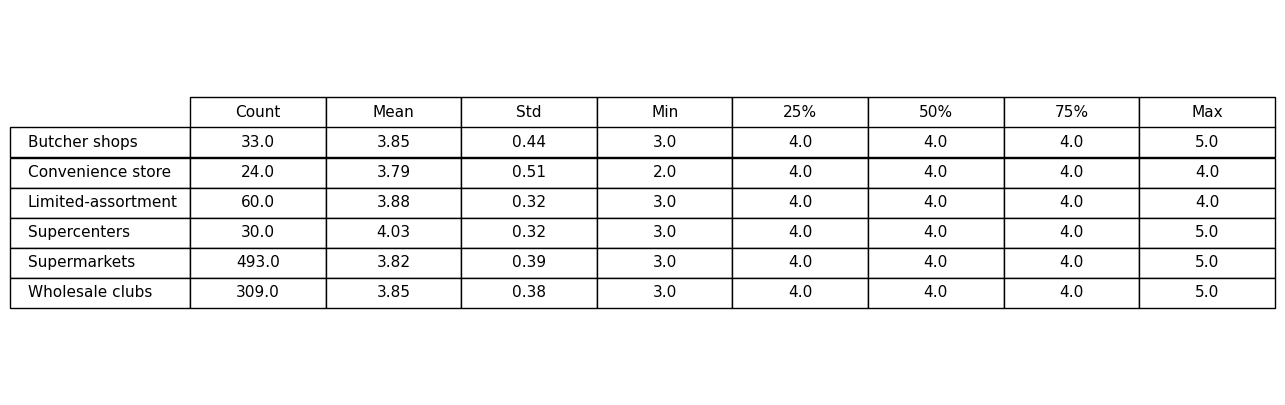

In [3346]:
import matplotlib.pyplot as plt

# Translate Retailer Types to English for Reporting
# Define the mapping dictionary (if not already defined globally)
mapping_dict = {
    "Acougue": "Butcher shops",
    "Atacarejo/Clubes": "Wholesale clubs",
    "Conveniência": "Convenience store",
    "Hiper/Supercenter": "Supercenters",
    "Sortimento limitado": "Limited-assortment",
    "Supermercado": "Supermarkets"
}

#Apply translation to a copy of the dataframe to avoid SettingWithCopy warnings
carne_bovina_data_clean = carne_bovina_data_clean.copy()
carne_bovina_data_clean["porte_loja"] = carne_bovina_data_clean["porte_loja"].replace(mapping_dict)

#Calculate Descriptive Statistics
# Group by Retailer Size and describe the Sanitary Performance Score
result = carne_bovina_data_clean.groupby("porte_loja")["est_desempenho_sanitario"].describe()

# Display the result in the notebook
print("Descriptive Statistics for Sanitary Performance (Beef Only):")
print(result)

#Save the Descriptive Table as an Image (Publication Ready)
fig, ax = plt.subplots(figsize=(14, 5)) 
ax.axis("tight")
ax.axis("off")

#Create the table
table = ax.table(
    cellText=result.round(2).values,  
    colLabels=result.columns.str.capitalize(), #
    rowLabels=result.index,
    loc="center",
    cellLoc="center"
)

# Style the table
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.8)  

# Save and Show
plt.savefig("saida/descricao_est_desempenho_sanitario_translated.png", dpi=300, bbox_inches="tight")
plt.show()

In [3347]:
#Visualizing Sanitary Performance by Retailer Size (Beef Only)

import plotly.express as px

#Translate Retailer Sizes
mapping_dict = {
    "Acougue": "Butcher shops",
    "Atacarejo/Clubes": "Wholesale clubs",
    "Conveniência": "Convenience store",
    "Hiper/Supercenter": "Supercenters",
    "Sortimento limitado": "Limited-assortment",
    "Supermercado": "Supermarkets"
}

#Apply translation to a copy to avoid warnings
carne_bovina_data_clean = carne_bovina_data_clean.copy()
carne_bovina_data_clean["porte_loja"] = carne_bovina_data_clean["porte_loja"].replace(mapping_dict)

#Prepare Data (Crosstab)
ct = pd.crosstab(
    carne_bovina_data_clean["porte_loja"],
    carne_bovina_data_clean["est_desempenho_sanitario"],
    normalize="index"
)

#Rename columns (Sanitary Scores)
sanitary_performance_labels = {
    2.0: "Poor",
    3.0: "Could be better",
    4.0: "Good",
    5.0: "Very good"
}
ct_renamed = ct.rename(columns=sanitary_performance_labels)

#Create Chart with High-Quality Base Settings
custom_colors = [
    "#ADD8E6",  # Light blue (Poor)
    "#87CEEB",  # Sky blue (Could be better)
    "#4682B4",  # Steel blue (Good)
    "#00008B"   # Dark blue (Very good)
]

fig = px.bar(
    ct_renamed,
    barmode="relative", # Stacked
    color_discrete_sequence=custom_colors,
    height=700,
    width=1000,
    template="plotly_white" # Clean white background base
)

#Enhance Visuals & Definition
fig.update_layout(
    # Typography
    font=dict(family="Arial", size=14, color="black"),

    # Titles and Labels
    xaxis_title="",
    yaxis_title="Frequency",
    legend_title="Sanitary Performance Scale",

    # Axis Formatting
    xaxis=dict(
        tickangle=45,
        tickfont=dict(size=14),
        showgrid=False,
        linecolor="black", # Solid axis line
        linewidth=1
    ),
    yaxis=dict(
        showgrid=True,
        gridcolor="#E0E0E0", # Very soft grey grid
        gridwidth=1,
        tickformat=".0%",    # Percentage format
        linecolor="black",   # Solid axis line
        linewidth=1,
        zeroline=False
    ),

    # Legend Styling
    legend=dict(
        x=1.02,
        y=1,
        bgcolor="rgba(255, 255, 255, 0.9)",
        bordercolor="#CCCCCC",
        borderwidth=1,
        font=dict(size=12)
    ),

    # Layout Spacing
    margin=dict(l=80, r=150, t=50, b=100), # Increased right margin for legend
    bargap=0.2, # Space between bars
)

#Add Borders to Bars (Crucial for "Crisp" look)
fig.update_traces(
    marker_line_color='white',
    marker_line_width=1.5,
    hovertemplate=(
        "<b>Store Size</b>: %{x}<br>"
        "<b>Rating</b>: %{data.name}<br>"
        "<b>Frequency</b>: %{y:.1%}<extra></extra>"
    )
)  

#Save in High Definition
# Option A: High-Res PNG (Scale 6 = 600 DPI approx)
try:
    fig.write_image("saida/Sanitary_high_res.png", scale=6)
except Exception as e:
    print(f"Could not save image (check kaleido installation): {e}")

# Option B: Vector Format (Infinite resolution, best for PDF papers)
try:
    fig.write_image("saida/descritiva_hip2.svg")
except Exception as e:
    print(f"Could not save SVG: {e}")

fig.show()

In [3348]:
import statsmodels.api as sm
import pandas as pd
from statsmodels.miscmodels.ordinal_model import OrderedModel 
import numpy as np

#Handle Dummies 
if 'porte_loja' in carne_bovina_data_clean.columns:
    carne_bovina_data_clean = pd.get_dummies(
        carne_bovina_data_clean, 
        columns=["porte_loja"], 
        drop_first=True # Keeps one category as the reference (Butcher shops)
    )
    print("Dummies created/regenerated.")
else:
    print("Dummies already exist (Skipping pd.get_dummies).")

#Prepare the predictor (X) and response (Y) variables
dummy_columns = [col for col in carne_bovina_data_clean.columns if "porte_loja_" in col]
independent_vars = dummy_columns + ["renda_setor"]

#Define X (Predictors)
X_olr = carne_bovina_data_clean[independent_vars].copy() 

#Define Y (Response): Must be integer for OLR (1, 2, 3, 4, 5)
y_olr = carne_bovina_data_clean["est_desempenho_sanitario"].astype(int)

#Ensure X is FLOAT
X_olr = X_olr.astype(float) # Ensure all predictors are float (preserves income precision)

#Fit the Ordinal Logistic Regression Model (OLR)
print("Fitting Ordinal Logistic Regression (OLR)...")
try:
    # Use distr='logit' for the Proportional Odds Model (standard OLR)
    modelo_olr = OrderedModel(y_olr, X_olr, distr='logit').fit(method='bfgs')
    
    # Display the statistical summary
    print(modelo_olr.summary())

except Exception as e:
    print(f"Error fitting OLR model: {e}")

Dummies created/regenerated.
Fitting Ordinal Logistic Regression (OLR)...
Optimization terminated successfully.
         Current function value: 0.493272
         Iterations: 66
         Function evaluations: 71
         Gradient evaluations: 71
                                OrderedModel Results                                
Dep. Variable:     est_desempenho_sanitario   Log-Likelihood:                -468.11
Model:                         OrderedModel   AIC:                             954.2
Method:                  Maximum Likelihood   BIC:                             997.9
Date:                      Wed, 03 Dec 2025                                         
Time:                              15:57:03                                         
No. Observations:                       949                                         
Df Residuals:                           940                                         
Df Model:                                 6                               

In [3349]:
#Preparing null model
model_null = OrderedModel(carne_bovina_data_clean['est_desempenho_sanitario'], exog=None, # No independent variables
                          distr='logit')
results_null = model_null.fit()
print(results_null.summary())

Optimization terminated successfully.
         Current function value: 0.500374
         Iterations: 55
         Function evaluations: 98
                                OrderedModel Results                                
Dep. Variable:     est_desempenho_sanitario   Log-Likelihood:                -474.85
Model:                         OrderedModel   AIC:                             955.7
Method:                  Maximum Likelihood   BIC:                             970.3
Date:                      Wed, 03 Dec 2025                                         
Time:                              15:57:03                                         
No. Observations:                       949                                         
Df Residuals:                           946                                         
Df Model:                                 0                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------

In [3350]:
import numpy as np
import pandas as pd
import scipy.stats as stats # Required for the Chi-squared test

# Assuming 'modelo_olr' is your fitted full OLR model (Ordinal Logistic Regression)
# and 'results_null' is your fitted null OLR model from the previous step.

#Obtain Log-Likelihood values
LL = modelo_olr.llf       # Log-Likelihood of the Full Model
LL_null = results_null.llf # Log-Likelihood of the Null Model

#Calculate McFadden's Pseudo R-Squared
pseudo_r2 = 1 - (LL / LL_null)

#Calculate the Likelihood Ratio (LR) Test Statistic
# LR Test Statistic: LR = -2 * (LL_null - LL)
LR_statistic = -2 * (LL_null - LL)

#Determine Degrees of Freedom (df) for the test
df_lr = modelo_olr.df_model # Provides the correct df (number of predictors)

#Calculate the p-value using the Chi-squared distribution
# sf is the survival function (1 - CDF), giving the upper-tail probability (the p-value)
lr_p_value = stats.chi2.sf(LR_statistic, df=df_lr)

print("--- Overall Model Quality & Likelihood Ratio Test ---")
print(f"1. Log-Likelihood (LL) of Full Model: {LL:.4f}")
print(f"2. Log-Likelihood of Null Model (LL_null): {LL_null:.4f}")
print("-" * 50)
print(f"McFadden's Pseudo R-Squared: {pseudo_r2:.6f}")
print(f"LR Test Statistic (Chi²): {LR_statistic:.4f}")
print(f"Degrees of Freedom (df): {df_lr}")
print(f"LR Test P-value: {lr_p_value:.6f}") # Output from the second block

# --- Interpretation Note ---
if lr_p_value < 0.05:
    print("\nCONCLUSION: The Full Model is statistically better than the Null Model.")
else:
     print("\nCONCLUSION: The Full Model is NOT statistically better than the Null Model (LLR p > 0.05).")

if pseudo_r2 < 0.20:
    print(
        "NOTE on R²: The Pseudo R-Squared is low (<0.20), indicating limited "
        "explanatory power, even if the model is technically significant."
    )

--- Overall Model Quality & Likelihood Ratio Test ---
1. Log-Likelihood (LL) of Full Model: -468.1150
2. Log-Likelihood of Null Model (LL_null): -474.8548
--------------------------------------------------
McFadden's Pseudo R-Squared: 0.014193
LR Test Statistic (Chi²): 13.4797
Degrees of Freedom (df): 6
LR Test P-value: 0.036020

CONCLUSION: The Full Model is statistically better than the Null Model.
NOTE on R²: The Pseudo R-Squared is low (<0.20), indicating limited explanatory power, even if the model is technically significant.


## Conclusion 

In conclusion, the hypothesis that sanitary quality uniformly improves with increasing establishment size was not broadly confirmed. Instead, the data points to a general high baseline of sanitary performance across most retailer types, with only the Supercenter category demonstrating a distinct and statistically significant advantage. The very limited explanatory power of the model (low Pseudo R2) further suggests that other, uninvestigated factors likely exert a far more dominant influence on the determination of sanitary quality within these establishments.